Lade Daten...
Original: C:\myBox\Projekte\FHDW\Kurs_DAML\Vorlesung_V11\python\Ameshousing.csv -> 2930 Zeilen, 82 Spalten
Cleaned:  C:\myBox\Projekte\FHDW\Kurs_DAML\Vorlesung_V11\python\Ames_Num_Best_DropFirst.csv -> 2925 Zeilen, 206 Spalten
Bilder:   C:\myBox\Projekte\python\Daten\Ames\Bilder -> 2854 vorhanden, 2930 erwartet (76 fehlend)



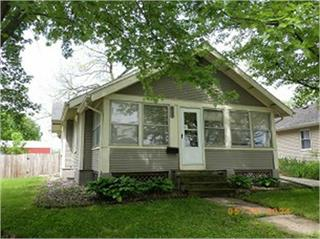

Output()

Output()

Output()

Output()

In [ ]:
import pandas as pd
import numpy as np
import os
import base64
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler   # <-- erweitert
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from scipy.spatial.distance import cdist
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display, HTML, clear_output
import ipywidgets as widgets
import warnings
warnings.filterwarnings('ignore')
_ = pd.set_option('display.max_columns', None)
_ = pd.set_option('display.min_rows', 8)
_ = pd.set_option('display.max_rows', 500)

# ----------------------------- Hilfsfunktionen ---------------------------------

# ----- Lookup-Tabellen für kategoriale Variablen (unverändert) -----
MS_SUBCLASS_MAP = {
    20: "1-STORY 1946 & NEWER ALL STYLES",
    30: "1-STORY 1945 & OLDER",
    40: "1-STORY W/FINISHED ATTIC ALL AGES",
    45: "1-1/2 STORY - UNFINISHED ALL AGES",
    50: "1-1/2 STORY FINISHED ALL AGES",
    60: "2-STORY 1946 & NEWER",
    70: "2-STORY 1945 & OLDER",
    75: "2-1/2 STORY ALL AGES",
    80: "SPLIT OR MULTI-LEVEL",
    85: "SPLIT FOYER, geteiltem Eingangsbereich",
    90: "DUPLEX - ALL STYLES AND AGES (Doppelhäuser)",
    120: "1-STORY PUD (Planned Unit Development) - 1946 & NEWER",
    150: "1-1/2 STORY PUD - ALL AGES, PUD (Planned Unit Development): Wohnanlage,",
    160: "2-STORY PUD - 1946 & NEWER",
    180: "PUD - MULTILEVEL - INCL SPLIT LEV/FOYER",
    190: "2 FAMILY CONVERSION - ALL STYLES AND AGES"
}

MS_ZONING_MAP = {
    'A': "Agriculture",
    'C': "Commercial",
    'FV': "Floating Village Residential, Wohnsiedlung auf Wasser gebaut",
    'I': "Industrial",
    'RH': "Residential High Density",
    'RL': "Residential Low Density",
    'RP': "Residential Low Density Park",
    'RM': "Residential Medium Density"
}

ALLEY_MAP = {
    'Grvl': "Gravel, Kiesweg",
    'Pave': "Paved, Gepflastert, befestigt",
    'NA': "No alley access"
}

LOT_SHAPE_MAP = {
    'Reg': "Regular",
    'IR1': "Slightly irregular",
    'IR2': "Moderately Irregular",
    'IR3': "Irregular"
}

LAND_CONTOUR_MAP = {
    'Lvl': "Near Flat/Level",
    'Bnk': "Banked - Quick and significant rise from street grade (Bodenniveau) to building",
    'HLS': "Hillside - Significant slope from side to side",
    'Low': "Depression"
}

UTILITIES_MAP = {
    'AllPub': "All public Utilities (E,G,W,& S)",
    'NoSewr': "Electricity, Gas, and Water (Septic Tank)",
    'NoSeWa': "Electricity and Gas Only",
    'ELO': "Electricity only"
}

LOT_CONFIG_MAP = {
    'Inside': "Inside lot",
    'Corner': "Corner lot",
    'CulDSac': "Cul-de-sac [Sackgasse]",
    'FR2': "Frontage on 2 sides of property",
    'FR3': "Frontage on 3 sides of property"
}

LAND_SLOPE_MAP = {
    'Gtl': "Gentle slope",
    'Mod': "Moderate Slope",
    'Sev': "Severe Slope"
}

NEIGHBORHOOD_MAP = {
    'Blmngtn': "Bloomington Heights",
    'Blueste': "Bluestem",
    'BrDale': "Briardale",
    'BrkSide': "Brookside",
    'ClearCr': "Clear Creek",
    'CollgCr': "College Creek",
    'Crawfor': "Crawford",
    'Edwards': "Edwards",
    'Gilbert': "Gilbert",
    'Greens': "Greens",
    'GrnHill': "Green Hills",
    'IDOTRR': "Iowa Department of Transportation (DOT) and Rail Road",
    'Landmrk': "Landmark",
    'MeadowV': "Meadow Village",
    'Mitchel': "Mitchell",
    'Names': "North Ames",
    'NoRidge': "Northridge",
    'NPkVill': "Northpark Villa",
    'NridgHt': "Northridge Heights",
    'NWAmes': "Northwest Ames",
    'OldTown': "Old Town",
    'SWISU': "South & West of Iowa State University",
    'Sawyer': "Sawyer",
    'SawyerW': "Sawyer West",
    'Somerst': "Somerset",
    'StoneBr': "Stone Brook",
    'Timber': "Timberland",
    'Veenker': "Veenker"
}

CONDITION_MAP = {
    'Artery': "Adjacent to arterial street, Hauptstraße",
    'Feedr': "Adjacent to feeder street, Zubringerstraße",
    'Norm': "Normal",
    'RRNn': "Within 200' of North-South Railroad",
    'RRAn': "Adjacent to North-South Railroad",
    'PosN': "Near positive off-site feature--park, greenbelt, etc.",
    'PosA': "Adjacent to postive off-site feature",
    'RRNe': "Within 200' of East-West Railroad",
    'RRAe': "Adjacent to East-West Railroad"
}

BLDG_TYPE_MAP = {
    '1Fam': "Single-family Detached",
    '2FmCon': "Two-family Conversion; originally built as one-family dwelling",
    'Duplx': "Duplex (Doppelhaus)",
    'TwnhsE': "Townhouse End Unit (Reihenhaus)",
    'TwnhsI': "Townhouse Inside Unit"
}

HOUSE_STYLE_MAP = {
    '1Story': "One story",
    '1.5Fin': "One and one-half story: 2nd level finished",
    '1.5Unf': "One and one-half story: 2nd level unfinished",
    '2Story': "Two story",
    '2.5Fin': "Two and one-half story: 2nd level finished",
    '2.5Unf': "Two and one-half story: 2nd level unfinished",
    'SFoyer': "Split Foyer. zwei Ebenen, die über ein gemeinsames, geteiltes Foyer",
    'SLvl': "Split Level. mehrstufigen Split‑Level‑Hauses, mehrere halbversetzte Etage"
}

OVERALL_QUAL_COND_MAP = {
    10: "Very Excellent",
    9: "Excellent",
    8: "Very Good",
    7: "Good",
    6: "Above Average",
    5: "Average",
    4: "Below Average",
    3: "Fair",
    2: "Poor",
    1: "Very Poor"
}

EXTERIOR_MAP = {
    'AsbShng': "Asbestos Shingles (Asbestschieferplatte)",
    'AsphShn': "Asphalt Shingles Bitumenschindeln",
    'BrkComm': "Brick Common Ziegel (Standard)",
    'BrkFace': "Brick Face (Verblendziegel)",
    'CBlock': "Cinder Block (Betonschlackehohlstein)",
    'CemntBd': "Cement Board (Betonplatte)",
    'HdBoard': "Hard Board Hartfaserplatte",
    'ImStucc': "zementbasierten Putzsystem, Stucco",
    'MetalSd': "Metal Siding Metallverkleidung",
    'Other': "Other",
    'Plywood': "Plywood (Sperrholz)",
    'PreCast': "PreCast (Betonfertigteil)",
    'Stone': "Stone",
    'Stucco': "Stucco Stuck",
    'VinylSd': "Vinyl Siding (Kunststoffverkleidung)",
    'Wd Sdng': "Wood Siding",
    'WdShing': "Wood Shingles Holzschindeln"
}

MAS_VNR_TYPE_MAP = {
    'BrkCmn': "Brick Common, Ziegel (Standard)",
    'BrkFace': "Brick Face, Ziegel (Verblendung)",
    'CBlock': "Cinder Block Betonblock (Hohlblock)",
    'None': "None",
    'Stone': "Stone"
}

EXTER_QUAL_COND_MAP = {
    'Ex': "Excellent",
    'Gd': "Good",
    'TA': "Average/Typical",
    'Fa': "Fair",
    'Po': "Poor"
}

FOUNDATION_MAP = {
    'BrkTil': "Brick & Tile, Ziegel & Fliesen",
    'CBlock': "Cinder Block, Betonblock",
    'PConc': "Poured Contrete, Gegossener Beton",
    'Slab': "Betonplatte",
    'Stone': "Stein",
    'Wood': "Holz"
}

BSMT_QUAL_COND_EXPOSURE_MAP = {
    'Ex': "Excellent",
    'Gd': "Good",
    'TA': "Typical/Average",
    'Fa': "Fair",
    'Po': "Poor",
    'NA': "No Basement"
}

BSMT_EXPOSURE_MAP = {
    'Gd': "Good Exposure, Gute Belichtung",
    'Av': "Average Exposure (split levels or foyers typically score average or above)",
    'Mn': "Minimum Exposure",
    'No': "No Exposure, Keine Belichtung",
    'NA': "No Basement"
}

BSMT_FIN_TYPE_MAP = {
    'GLQ': "Good Living Quarters, hochwertig ausgebauter Keller",
    'ALQ': "Average Living Quarters",
    'BLQ': "Below Average Living Quarters",
    'Rec': "Average Rec Room, Durchschnittlicher Freizeitraum",
    'LwQ': "Low Quality",
    'Unf': "Unfinished",
    'NA': "No Basement"
}

HEATING_MAP = {
    'Floor': "Floor Furnace (Fußbodenwarmluftheizung)",
    'GasA': "Gas forced warm air furnace",
    'GasW': "Gas hot water or steam heat, Gas-Zentralheizung",
    'Grav': "Gravity furnace (Innenwarmluftheizung)",
    'OthW': "Hot water or steam heat other than gas",
    'Wall': "Wall furnace, Wandwarmluftheizung, Außenwandwarmluftheizung"
}

HEATING_QC_MAP = EXTER_QUAL_COND_MAP

ELECTRICAL_MAP = {
    'SBrkr': "Standard Circuit Breakers & Romex",
    'FuseA': "Fuse Box over 60 AMP and all Romex wiring (Average)",
    'FuseF': "60 AMP Fuse Box and mostly Romex wiring (Fair)",
    'FuseP': "60 AMP Fuse Box and mostly knob & tube wiring (poor)",
    'Mix': "Mixed"
}

KITCHEN_QUAL_MAP = EXTER_QUAL_COND_MAP

FUNCTIONAL_MAP = {
    'Typ': "Typical Functionality",
    'Min1': "Minor Deductions 1",
    'Min2': "Minor Deductions 2",
    'Mod': "Moderate Deductions",
    'Maj1': "Major Deductions 1",
    'Maj2': "Major Deductions 2",
    'Sev': "Severely Damaged",
    'Sal': "Salvage only (nur Abbruch möglich)"
}

FIREPLACE_QU_MAP = {
    'Ex': "Excellent - Exceptional Masonry Fireplace",
    'Gd': "Good - Masonry Fireplace in main level",
    'TA': "Average - Prefabricated Fireplace in main living area or Masonry Fireplace in basement",
    'Fa': "Fair - Prefabricated Fireplace in basement",
    'Po': "Poor - Ben Franklin Stove",
    'NA': "No Fireplace"
}

GARAGE_TYPE_MAP = {
    '2Types': "More than one type of garage",
    'Attchd': "Attached to home",
    'Basment': "Basement Garage",
    'BuiltIn': "Built-In (Garage part of house - typically has room above garage)",
    'CarPort': "Car Port",
    'Detchd': "Detached from home",
    'NA': "No Garage"
}

GARAGE_FINISH_MAP = {
    'Fin': "Finished",
    'RFn': "Rough Finished",
    'Unf': "Unfinished",
    'NA': "No Garage"
}

GARAGE_COND_MAP = EXTER_QUAL_COND_MAP

PAVED_DRIVE_MAP = {
    'Y': "Paved, Gepflastert / Asphaltiert",
    'P': "Partial Pavement",
    'N': "Dirt/Gravel, Unbefestigt (Schotter oder Erde)"
}

POOL_QC_MAP = EXTER_QUAL_COND_MAP

FENCE_MAP = {
    'GdPrv': "Good Privacy",
    'MnPrv': "Minimum Privacy",
    'GdWo': "Good Wood",
    'MnWw': "Minimum Wood/Wire",
    'NA': "No Fence"
}

MISC_FEATURE_MAP = {
    'Elev': "Elevator",
    'Gar2': "2nd Garage (if not described in garage section)",
    'Othr': "Other",
    'Shed': "Shed (over 100 SF), Schuppen",
    'TenC': "Tennis Court",
    'NA': "None"
}

SALE_TYPE_MAP = {
    'WD': "Warranty Deed – Conventional (Übertragungsurkunde mit Garantien)",
    'CWD': "Warranty Deed – Cash, Grundstücksübertragung gegen Sofortzahlung mit Rechtsgarantien",
    'VWD': "Warranty Deed - VA Loan (Veterans Affairs), Grundstücksübertragung mit Garantien für VA-Veterendarlehen",
    'New': "Home just constructed and sold, Neubau",
    'COD': "Court Officer Deed/Estate, Amtliche Eigentumsübertragung durch Gericht/Nachlassverwaltung",
    'Con': "Contract 15% Down payment regular terms, Anzahlung mit Ratenzahlung",
    'ConLw': "Contract Low Down payment and low interest, geringe Anzahlung und niedriger Zins",
    'ConLI': "Contract Low Interest (Hypothek mit günstigem Zinssatz)",
    'ConLD': "Contract Low Down, Finanzierung mit niedrigem Eigenkapitalanteil",
    'Oth': "Other"
}

SALE_CONDITION_MAP = {
    'Normal': "Normal Sale",
    'Abnorml': "Abnormal Sale, foreclosure (Zwangsvollstreckung), short sale (ohne Hypotheken)",
    'AdjLand': "Adjoining Land Purchase, eigentlich ohne Bebauung. Die 12 Verkäufe in Ames sind jedoch alle mit einfacher Bebauung",
    'Alloca': "Allocation - two linked properties with separate deeds, typically condo with a garage unit",
    'Family': "Sale between family members",
    'Partial': "Home was not completed when last assessed (associated with New Homes)"
}

def debug_print(message, enabled=False):
    if enabled:
        print(f"DEBUG: {message}")

def decode_value(var_name, value):
    """
    Dekodiert einen kategorialen Wert anhand des Variablennamens.
    Gibt einen String zurück: entweder den Originalwert oder "Wert [Bedeutung]".
    Für One-Hot-Namen (var_name enthält '_') wird der Suffix mit der Map des Präfix dekodiert.
    """
    if pd.isna(value):
        return "<nicht vorhanden>" if value is None else str(value)
    value = str(value).strip()

    if '_' in var_name:
        # Trenne in Präfix und Suffix
        prefix, suffix = var_name.split('_', 1)
        # Dekodiere den Suffix mit der Map des Präfix
        decoded_suffix = decode_value(prefix, suffix)  # rekursiver Aufruf mit Basisname
        # Wenn der dekodierte Wert vom Suffix abweicht, zeige "Suffix [Bedeutung]"
        if decoded_suffix != suffix:
            return f"{suffix} [{decoded_suffix}]"
        else:
            return suffix

    
    # Mapping auswählen
    mapping = None
    key = value

    # Numerische Schlüssel behandeln
    if var_name == 'MS SubClass':
        mapping = MS_SUBCLASS_MAP
        try:
            key = int(float(value))
        except:
            return str(value)
    elif var_name == 'MS Zoning':
        mapping = MS_ZONING_MAP
    elif var_name == 'Alley':
        mapping = ALLEY_MAP
    elif var_name == 'Lot Shape':
        mapping = LOT_SHAPE_MAP
    elif var_name == 'Land Contour':
        mapping = LAND_CONTOUR_MAP
    elif var_name == 'Utilities':
        mapping = UTILITIES_MAP
    elif var_name == 'Lot Config':
        mapping = LOT_CONFIG_MAP
    elif var_name == 'Land Slope':
        mapping = LAND_SLOPE_MAP
    elif var_name == 'Neighborhood':
        mapping = NEIGHBORHOOD_MAP
    elif var_name in ['Condition 1', 'Condition 2']:
        mapping = CONDITION_MAP
    elif var_name == 'Bldg Type':
        mapping = BLDG_TYPE_MAP
    elif var_name == 'House Style':
        mapping = HOUSE_STYLE_MAP
    elif var_name in ['Overall Qual', 'Overall Cond']:
        mapping = OVERALL_QUAL_COND_MAP
        try:
            key = int(float(value))
        except:
            return str(value)
    elif var_name in ['Exterior 1st', 'Exterior 2nd']:
        mapping = EXTERIOR_MAP
    elif var_name == 'Mas Vnr Type':
        mapping = MAS_VNR_TYPE_MAP
    elif var_name in ['Exter Qual', 'Exter Cond']:
        mapping = EXTER_QUAL_COND_MAP
    elif var_name == 'Foundation':
        mapping = FOUNDATION_MAP
    elif var_name in ['Bsmt Qual', 'Bsmt Cond']:
        mapping = BSMT_QUAL_COND_EXPOSURE_MAP
    elif var_name == 'Bsmt Exposure':
        mapping = BSMT_EXPOSURE_MAP
    elif var_name in ['BsmtFin Type 1', 'BsmtFin Type 2']:
        mapping = BSMT_FIN_TYPE_MAP
    elif var_name == 'Heating':
        mapping = HEATING_MAP
    elif var_name == 'Heating QC':
        mapping = HEATING_QC_MAP
    elif var_name == 'Electrical':
        mapping = ELECTRICAL_MAP
    elif var_name == 'Kitchen Qual':
        mapping = KITCHEN_QUAL_MAP
    elif var_name == 'Functional':
        mapping = FUNCTIONAL_MAP
    elif var_name == 'Fireplace Qu':
        mapping = FIREPLACE_QU_MAP
    elif var_name == 'Garage Type':
        mapping = GARAGE_TYPE_MAP
    elif var_name == 'Garage Finish':
        mapping = GARAGE_FINISH_MAP
    elif var_name in ['Garage Cond', 'Garage Qual']:
        mapping = GARAGE_COND_MAP
    elif var_name == 'Paved Drive':
        mapping = PAVED_DRIVE_MAP
    elif var_name == 'Pool QC':
        mapping = POOL_QC_MAP
    elif var_name == 'Fence':
        mapping = FENCE_MAP
    elif var_name == 'Misc Feature':
        mapping = MISC_FEATURE_MAP
    elif var_name == 'Sale Type':
        mapping = SALE_TYPE_MAP
    elif var_name == 'Sale Condition':
        mapping = SALE_CONDITION_MAP
    # Für Variablen ohne Mapping: unverändert
    else:
        return str(value)

    if mapping and key in mapping:
        return f"{value} [{mapping[key]}]"
    else:
        return str(value)

def image_to_base64(image_path):
    """Liest Bilddatei und gibt Base64-kodierten String zurück."""
    with open(image_path, "rb") as f:
        return base64.b64encode(f.read()).decode('utf-8')

def get_value(variable, orig_row, clean_row):
    """
    Ermittelt den Wert einer Variable aus orig_row und clean_row.
    Für One-Hot-Spalten (mit '_') wird der Wert "True" statt "1" angezeigt.
    """
    orig_str = None
    clean_str = None

    def format_pid_if_number(s):
        if s is None or s == "NaN":
            return s
        try:
            num = int(float(s))
            return format_pid(num)
        except:
            return s

    # Orig durchsuchen
    if orig_row is not None:
        variants = [variable, variable.replace(' ', '')]
        for v in variants:
            if v in orig_row.index:
                val = orig_row[v]
                if pd.isna(val):
                    orig_str = "NaN"
                else:
                    orig_str = str(val)
                break

    # Clean durchsuchen
    if clean_row is not None:
        variants = [variable, variable.replace(' ', '')]
        for v in variants:
            if v in clean_row.index:
                val = clean_row[v]
                if pd.isna(val):
                    clean_str = "NaN"
                else:
                    clean_str = str(val)
                break

    # --- NEU: One‑Hot‑Spalten: 1 → True ---
    if variable is not None and '_' in variable:
        if clean_str is not None:
            try:
                if float(clean_str) == 1:
                    clean_str = "True"
            except:
                pass
        if orig_str is not None:
            try:
                if float(orig_str) == 1:
                    orig_str = "True"
            except:
                pass

    # Spezialfall PID
    if variable == 'PID':
        if orig_str is not None and clean_str is not None:
            orig_str = format_pid_if_number(orig_str)
            clean_str = format_pid_if_number(clean_str)
            return f"{orig_str} ({clean_str})"
        elif orig_str is not None:
            return format_pid_if_number(orig_str)
        elif clean_str is not None:
            return f"({format_pid_if_number(clean_str)})"
        else:
            return "<nicht vorhanden>"

    # Normale Zusammenstellung
    if orig_str is None and clean_str is None:
        return "<nicht vorhanden>"
    elif orig_str is not None and clean_str is not None:
        return f"{orig_str} ({clean_str})"
    elif orig_str is not None:
        return orig_str
    else:
        return f"({clean_str})"

def format_pid(pid):
    """Formatiert PID auf 10 Stellen mit führenden Nullen (für den Assessor-Link)."""
    return str(int(pid)).zfill(10)

def create_text_block(title, items, orig_row, clean_row):
    """
    Erzeugt einen HTML-Block mit einer Liste von Variablen.
    items: Liste von Variablennamen (Basisnamen)
    Für One-Hot-encodierte Variablen wird der Wert aus den Spalten mit Unterstrich ermittelt.
    """
    # Sammle alle Spaltennamen aus orig und clean
    all_columns = set()
    if orig_row is not None:
        all_columns.update(orig_row.index)
    if clean_row is not None:
        all_columns.update(clean_row.index)
    
    # Gruppiere One-Hot-Spalten nach Basisname (alles vor erstem Unterstrich)
    onehot_groups = {}
    for col in all_columns:
        if '_' in col:
            base = col.split('_')[0].strip()
            onehot_groups.setdefault(base, []).append(col)
    
    html = "<div style='border:1px solid #ccc; padding:10px; margin:5px; flex:1;'>"
    html += f"<h4>{title}</h4>"
    html += "<ul style='list-style-type:none; padding-left:0;'>"
    
    for var in items:
        # Zuerst prüfen, ob es eine One-Hot-Gruppe für diesen Basisnamen gibt
        if var in onehot_groups:
            # One-Hot-Fall: Suche nach der aktiven Kategorie (Spalte mit Wert 1)
            orig_val = None
            clean_val = None
            
            # In orig_row suchen
            if orig_row is not None:
                for col in onehot_groups[var]:
                    if col in orig_row.index and pd.notna(orig_row[col]) and orig_row[col] == 1:
                        suffix = col.split('_', 1)[1]
                        # Dekodiere den Suffix (falls vorhanden)
                        decoded = decode_value(var, suffix)
                        orig_val = f"{suffix} [{decoded}]" if decoded != suffix else suffix
                        break
            # In clean_row suchen
            if clean_row is not None:
                for col in onehot_groups[var]:
                    if col in clean_row.index and pd.notna(clean_row[col]) and clean_row[col] == 1:
                        suffix = col.split('_', 1)[1]
                        decoded = decode_value(var, suffix)
                        clean_val = f"{suffix} [{decoded}]" if decoded != suffix else suffix
                        break
            
            # Kombiniere orig_val und clean_val
            if orig_val is not None and clean_val is not None:
                val_display = f"{orig_val} ({clean_val})"
            elif orig_val is not None:
                val_display = orig_val
            elif clean_val is not None:
                val_display = f"({clean_val})"
            else:
                val_display = "<nicht vorhanden>"
            
            # Prüfen, ob die Information aus orig_row stammt (für Kursivsetzung)
            in_orig = False
            if orig_row is not None:
                for col in onehot_groups[var]:
                    if col in orig_row.index:
                        in_orig = True
                        break
            var_italic = not in_orig
            
            if var_italic:
                html += f"<li><b style='font-style:italic;'>{var}:</b> {val_display}</li>"
            else:
                html += f"<li><b>{var}:</b> {val_display}</li>"
        
        else:
            # Keine One-Hot-Gruppe -> normale Variable
            # Bestimme Wert mit get_value
            val = get_value(var, orig_row, clean_row)
            # Prüfen, ob Variable in orig_row vorhanden (auch mit NaN)
            in_orig = False
            if orig_row is not None:
                variants = [var, var.replace(' ', ''), var.upper(), var.lower()]
                for v in variants:
                    if v in orig_row.index:
                        in_orig = True
                        break
            var_italic = not in_orig

            # Dekodieren abhängig vom Format von val
            if val.startswith('(') and val.endswith(')'):
                inner = val[1:-1].strip()
                decoded_inner = decode_value(var, inner)
                val = f"({decoded_inner})"
            elif '(' in val and ')' in val and val.index('(') > 0:
                orig_part = val.split('(')[0].strip()
                clean_part = val.split('(')[1].split(')')[0].strip()
                orig_decoded = decode_value(var, orig_part)
                clean_decoded = decode_value(var, clean_part)
                val = f"{orig_decoded} ({clean_decoded})"
            else:
                val = decode_value(var, val)

            if var_italic:
                html += f"<li><b style='font-style:italic;'>{var}:</b> {val}</li>"
            else:
                html += f"<li><b>{var}:</b> {val}</li>"
    
    html += "</ul></div>"
    return html



def display_text_blocks(orig_row, clean_row, orig_filename, clean_filename):
    """Zeigt die drei Zeilen mit Textblöcken an.
       Ursprüngliche Variablen bleiben erhalten, aktive One‑Hot‑Spalten (Wert 1) werden zusätzlich eingefügt."""
    
    # Basis-Listen (ursprüngliche Variablen, unverändert)
    house_vars = ['Year Built', 'HouseAge', 'Year Remod/Add', 'HouseIsNew', 'HouseIsreModeled', 'HouseRemodelAge', 'RenovationNeeded',
                  'Gr Liv Area', 'Area1st2nd', 'Low Qual Fin SF',
                  'Overall Qual', 'Overall Cond', 'Foundation', 'Bldg Type',
                  'House Style', 'Functional', 'Misc Feature', 'Misc Val',
                  'Pool QC', 'Fence']
    lot_vars = ['Lot Area', 'Land Slope', 'Land Contour', 'Lot Config',
                'Lot Frontage', 'Neighborhood', 'NeighborhoodClass', 'MS Zoning', 'MS SubClass', 'Street', 'Paved Drive',
                'Alley', 'Condition 1', 'Condition 2', 'Railroad_Adjacent',
                'Railroad_Near', 'PosFeature_Adjacent', 'PosFeature_Near' ]
    sale_vars = ['SalePrice', 'Yr Sold', 'Mo Sold', 'Sale Type', 'Sale Condition']
    exterior_vars = ['Exter Qual', 'PorchSFTotal', 'Open Porch SF', 'Enclosed Porch',
                     'Wood Deck SF', 'Screen Porch', 'Mas Vnr Type', 'Mas Vnr Area',
                     'Exterior 1st', 'Exterior 2nd']
    interior_vars = ['Utilities', 'Heating', 'Heating QC', 'Electrical', 'Fireplaces', 'Fireplace Qu']
    roof_vars = ['Roof Style', 'Roof Matl']
    garage_vars = ['Garage Yr Blt', 'GarageAge', 'Garage Area', 'Garage Cars', 'Garage Type',
                   'Garage Finish', 'Garage Cond', 'Garage Qual']
    basement_vars = ['Total Bsmt SF', 'BsmtFin Type 1', 'BsmtFin Type 2', 'Bsmt Qual',
                     'Bsmt Cond', 'Bsmt Exposure', 'Bsmt Unf SF', 'BsmtFin SF 1',
                     'BsmtFin SF 2']
    bath_vars = ['TotRms AbvGrd', 'Bedroom AbvGr', 'BathroomsTotal', 'Full Bath', 'Half Bath', 'Bsmt Half Bath', 'Bsmt Full Bath', 'Kitchen AbvGr']
    
    # --- Sammle alle aktiven One-Hot-Variablen aus clean_row ---
    active_onehot = []
    if clean_row is not None:
        for col in clean_row.index:
            if '_' in col:
                val = clean_row[col]
                # Verbesserte Erkennung: bool/True oder 1
                if pd.notna(val):
                    if isinstance(val, (bool, np.bool_)) and val:
                        active_onehot.append(col)
                    elif val == 1:
                        active_onehot.append(col)
    
    # --- Erstelle Kopien der Basis-Listen und erweitere sie mit den aktiven One‑Hot‑Namen ---
    house_list = house_vars.copy()
    lot_list = lot_vars.copy()
    sale_list = sale_vars.copy()
    exterior_list = exterior_vars.copy()
    interior_list = interior_vars.copy()
    roof_list = roof_vars.copy()
    garage_list = garage_vars.copy()
    basement_list = basement_vars.copy()
    bath_list = bath_vars.copy()
    
    # --- Wörterbuch, um von Basisnamen zur entsprechenden Kopie zu gelangen ---
    block_map = {
        'Exterior': exterior_list,
        'Roof Style': roof_list,
        'Roof Matl': roof_list,
        'Bldg Type': house_list,
        'Foundation': house_list,
        'Functional': house_list,
        'Garage Type': garage_list,
        'Heating': interior_list,
        'House Style': house_list,
        'Mas Vnr Type': exterior_list,
        'Misc Feature': house_list,
        'Neighborhood': lot_list,
        'Sale Condition': sale_list,
        'Sale Type': sale_list,
        'Street': lot_list,
        # Falls weitere Basisnamen exakt in den Listen vorkommen, können sie hier ergänzt werden
    }
    
    # Funktion, um die passende Liste für einen Basisnamen zu finden
    def get_target_list(base):
        # Zuerst Spezialfälle aus block_map
        if base in block_map:
            return block_map[base]
        # Dann prüfen, ob der Basisname in einer der Basis-Listen vorkommt
        if base in house_vars:
            return house_list
        if base in lot_vars:
            return lot_list
        if base in sale_vars:
            return sale_list
        if base in exterior_vars:
            return exterior_list
        if base in interior_vars:
            return interior_list
        if base in roof_vars:
            return roof_list
        if base in garage_vars:
            return garage_list
        if base in basement_vars:
            return basement_list
        if base in bath_vars:
            return bath_list
        return None
    
    # --- One‑Hot‑Spalten hinzufügen ---
    for onehot_col in active_onehot:
        base = onehot_col.split('_')[0].strip()
        target_list = get_target_list(base)
        if target_list is not None:
            if onehot_col not in target_list:
                target_list.append(onehot_col)
                # Sofort prüfen, ob es jetzt in der Liste ist
    
    # --- Sortiere jede Liste alphabetisch ---
    house_list.sort()
    lot_list.sort()
    sale_list.sort()
    exterior_list.sort()
    interior_list.sort()
    roof_list.sort()
    garage_list.sort()
    basement_list.sort()
    bath_list.sort()
    
    # Blöcke mit den erweiterten Listen erstellen
    blocks = [
        ("Haus", house_list),
        ("Grundstück", lot_list),
        ("Verkauf", sale_list),
        ("Aussenausstattung", exterior_list),
        ("Innenausstattung", interior_list),
        ("Dach", roof_list),
        ("Garage", garage_list),
        ("Keller", basement_list),
        ("Räume", bath_list)
    ]
    
    # Erste Zeile
    block1 = create_text_block(blocks[0][0], blocks[0][1], orig_row, clean_row)
    block2 = create_text_block(blocks[1][0], blocks[1][1], orig_row, clean_row)
    block3 = create_text_block(blocks[2][0], blocks[2][1], orig_row, clean_row)
    display(HTML(f"<div style='display:flex;'>{block1}{block2}{block3}</div>"))
    
    # Zweite Zeile
    block4 = create_text_block(blocks[3][0], blocks[3][1], orig_row, clean_row)
    block5 = create_text_block(blocks[4][0], blocks[4][1], orig_row, clean_row)
    block6 = create_text_block(blocks[5][0], blocks[5][1], orig_row, clean_row)
    display(HTML(f"<div style='display:flex;'>{block4}{block5}{block6}</div>"))
    
    # Dritte Zeile
    block7 = create_text_block(blocks[6][0], blocks[6][1], orig_row, clean_row)
    block8 = create_text_block(blocks[7][0], blocks[7][1], orig_row, clean_row)
    block9 = create_text_block(blocks[8][0], blocks[8][1], orig_row, clean_row)
    display(HTML(f"<div style='display:flex;'>{block7}{block8}{block9}</div>"))
    
    # Link zur Assessor-Seite (unverändert)
    if orig_row is not None and 'PID' in orig_row.index and pd.notna(orig_row['PID']):
        formatted_pid = format_pid(orig_row['PID'])
        url = f"https://beacon.schneidercorp.com/Application.aspx?AppID=165&LayerID=2145&PageTypeID=4&PageID=1108&Q=332188569&KeyValue={formatted_pid}"
        display(HTML(f'<p><a href="{url}" target="_blank">🔗 Link zur Assessor-Seite (PID {formatted_pid})</a></p>'))
    else:
        display(HTML("<p>Keine PID verfügbar, Link kann nicht erstellt werden.</p>"))

    explanation = f"""
    <div style='margin-top:20px; padding:10px; background-color:#f0f0f0; border-radius:5px; font-size:0.9em;'>
        <p><b>Hinweis:</b> Die angezeigten Werte stammen aus der Originaldatei ({orig_filename}). 
        Falls in Klammern ein weiterer Wert angegeben ist (z. B. <code>2000 (1950)</code>), 
        stammt dieser aus der bereinigten (cleaned) Datei ({clean_filename}). <br>Kursiv geschriebene Variablennamen sind nicht in der Originaldatei vorhanden.</p>
    </div>
    """
    display(HTML(explanation))
    
# ----------------------------- Hauptdarstellungsfunktionen --------------------

def display_bild(order, orig_row, clean_row, pid, image_dir, orig_filename, clean_filename, show_missing_warning=True):
    """Bild-Darstellung: links Variablen, rechts Bild oder Fallback mit optionaler Warnung."""
    # PID sicher als Integer
    if pd.notna(pid):
        pid_int = int(pid)
        pid_str = format_pid(pid_int)
    else:
        pid_int = None
        pid_str = None

    # Linke Spalte (Haus-Informationen) – festere Breite und besserer Abstand
    sale_price = get_value('SalePrice', orig_row, clean_row)
    order_val = get_value('Order', orig_row, clean_row)
    pid_val = get_value('PID', orig_row, clean_row)
    left_html = f"""
    <div style='flex:0 0 280px; padding:15px; background-color:#fafafa; border-right:1px solid #ddd;'>
        <h3 style='margin-top:0; margin-bottom:15px; color:#333;'>Haus {order}</h3>
        <p style='margin:8px 0;'><b>SalePrice:</b> {sale_price}</p>
        <p style='margin:8px 0;'><b>Order:</b> {order_val}</p>
        <p style='margin:8px 0;'><b>PID:</b> {pid_val}</p>
    </div>
    """

    # Rechte Spalte: Bild oder Fallback
    if pid_str is not None:
        image_path = os.path.join(image_dir, f"{pid_str}_House.jpg")
        if os.path.exists(image_path):
            try:
                b64_data = image_to_base64(image_path)
                right_html = f"""
                <div style='flex:1; display:flex; justify-content:center; align-items:center; padding:15px;'>
                    <img src="data:image/jpeg;base64,{b64_data}" 
                         style='max-width:100%; max-height:350px; border:1px solid #ccc; box-shadow:2px 2px 5px rgba(0,0,0,0.1);'>
                </div>
                """
            except Exception as e:
                right_html = "<div style='flex:1; padding:15px; color:red;'>Fehler beim Kodieren: {e}</div>"
        else:
            if show_missing_warning:
                right_html = f"""
                <div style='flex:1; display:flex; gap:15px; padding:15px;'>
                    <div style='flex:1; border:1px solid #ff9800; padding:15px; background-color:#fff3e0; border-radius:4px;'>
                        <b style='color:#e65100;'>⚠️ Kein Bild gefunden</b><br>
                        <span style='font-size:0.9em;'>PID {pid_str} nicht im Verzeichnis:<br>
                        <code style='background:#eee; padding:2px 4px;'>{os.path.abspath(image_dir)}</code></span>
                    </div>
                    <div style='flex:1;'>
                        {create_fallback_textbox(orig_row, order)}
                    </div>
                </div>
                """
            else:
                fallback = create_fallback_textbox(orig_row, order)
                right_html = f"""
                <div style='flex:1; display:flex; justify-content:center; align-items:center; padding:15px;'>
                    {fallback}
                </div>
                """
    else:
        right_html = "<div style='flex:1; padding:15px; color:red;'>Keine PID vorhanden</div>"

    display(HTML(f"<div style='display:flex; margin:20px 0; border:1px solid #ccc; border-radius:6px; overflow:hidden; box-shadow:0 2px 5px rgba(0,0,0,0.1);'>{left_html}{right_html}</div>"))
    display_text_blocks(orig_row, clean_row, orig_filename, clean_filename)
    


def display_distributions(orig_df, current_row, order, neighbor_rows=None, plots_per_row=6, max_categories=30):
    """
    Zeigt für alle Spalten (außer Order, PID) Verteilungsgrafiken.
    - current_row: Zeile des aktuellen Hauses (rote Markierung)
    - neighbor_rows: Liste von Zeilen der Nachbarhäuser (grüne Markierungen)
    Die Variable 'Neighborhood' wird in einer separaten Grafik dargestellt.
    Im Hover für kategoriale Variablen wird jetzt angezeigt: Anzahl, ob aktuelles Haus in Kategorie, wie viele Nachbarn.
    """
    # Definiere die Liste der kategorialen Variablen (laut Aufgabenstellung)
    categorical_vars = [
        'Alley', 'Bedroom AbvGr', 'Bldg Type', 'Bsmt Cond', 'Bsmt Exposure', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Bsmt Qual',
        'BsmtFin Type 1', 'BsmtFin Type 2', 'Central Air', 'Condition 1', 'Condition 2', 'Electrical', 'Exterior 1st', 'Exterior 2nd', 'Exter Cond', 'Exter Qual',
        'Fence', 'Fireplace Qu', 'Fireplaces', 'Foundation', 'Full Bath', 'Functional', 'Garage Cars', 'Garage Cond', 'Garage Finish','Garage Type',
        'Garage Qual', 'Half Bath', 'Heating QC', 'Heating', 'House Style', 'Kitchen AbvGr', 'Kitchen Qual', 'Land Contour',
        'Land Slope', 'Lot Config', 'Lot Shape', 'MS SubClass', 'MS Zoning', 'Mas Vnr Type', 'Misc Feature', 'Mo Sold',
        'Neighborhood', 'Overall Cond', 'Overall Qual', 'Paved Drive', 'Pool QC', 'Roof Matl', 'Sale Condition', 'Sale Type',
        'Street', 'Utilities', 'Yr Sold'
    ]
    
    all_cols = [col for col in orig_df.columns if col not in ['Order', 'PID']]
    
    # Neighborhood separat behandeln (obwohl es in categorical_vars ist, bleibt der separate Plot erhalten)
    if 'Neighborhood' in all_cols:
        has_neighborhood = True
        all_cols.remove('Neighborhood')
    else:
        has_neighborhood = False

    all_cols = sorted(all_cols)

    if not all_cols and not has_neighborhood:
        display(HTML("<p>Keine Variablen für Verteilungen vorhanden.</p>"))
        return

    # ---------- Gruppen für alle anderen Variablen ----------
    for i in range(0, len(all_cols), plots_per_row):
        group = all_cols[i:i+plots_per_row]
        n_cols = len(group)

        fig = make_subplots(rows=1, cols=n_cols,
                            subplot_titles=group,
                            shared_yaxes=False)

        for j, col in enumerate(group, start=1):
            show_missing = False
            if current_row is not None and col in current_row.index and pd.isna(current_row[col]):
                show_missing = True

            data = orig_df[col].dropna()
            if data.empty:
                fig.add_annotation(text="Keine Daten", showarrow=False, row=1, col=j)
                continue

            # --- Werte für aktuelles Haus und Nachbarn holen, typgerecht ---
            # Ist die Spalte kategorial?
            is_categorical = col in categorical_vars

            # Wert des aktuellen Hauses
            current_val = None
            if current_row is not None and col in current_row.index and pd.notna(current_row[col]):
                val = current_row[col]
                if is_categorical:
                    current_val = str(val).strip()
                else:
                    try:
                        current_val = float(val)
                    except:
                        current_val = None

            # Nachbarwerte
            neighbor_vals = []
            if neighbor_rows is not None:
                for nb_row in neighbor_rows:
                    if col in nb_row.index and pd.notna(nb_row[col]):
                        val = nb_row[col]
                        if is_categorical:
                            neighbor_vals.append(str(val).strip())
                        else:
                            try:
                                neighbor_vals.append(float(val))
                            except:
                                pass

            if is_categorical:
                # ----- Kategoriale Variable: Balkendiagramm -----
                counts = data.value_counts()
                if len(counts) > max_categories:
                    counts = counts.head(max_categories)
                counts = counts.sort_index()
                categories = counts.index.astype(str)
                frequencies = counts.values

                # Farben: Standard blau
                colors = ['blue'] * len(categories)

                # Nachbarn markieren (grün)
                for val in neighbor_vals:
                    val_str = val.strip()
                    for idx, cat in enumerate(categories):
                        if cat == val_str:
                            colors[idx] = 'green'
                            break

                # Aktuelles Haus markieren (rot) – überschreibt grün
                if not show_missing and current_val is not None:
                    current_str = current_val.strip()
                    for idx, cat in enumerate(categories):
                        if cat == current_str:
                            colors[idx] = 'red'
                            break

                # ERWEITERTER HOVER-TEXT
                hover_texts = []
                for idx, cat in enumerate(categories):
                    base = decode_value(col, cat)
                    current_in_cat = (current_val == cat) if current_val is not None else False
                    neighbor_count = sum(1 for v in neighbor_vals if v == cat)
                    hover = f"Wert: {base}<br>Anzahl: {frequencies[idx]}<br>Aktuelles Haus: {'ja' if current_in_cat else 'nein'}<br>Nachbarn: {neighbor_count}"
                    hover_texts.append(hover)

                fig.add_trace(go.Bar(x=categories, y=frequencies,
                                     marker_color=colors,
                                     hovertext=hover_texts,
                                     hoverinfo='text',
                                     showlegend=False,
                                     name=col),
                              row=1, col=j)

                if len(categories) > 5:
                    fig.update_xaxes(tickangle=45, row=1, col=j)

            else:
                # ----- Numerische Variable: Histogramm -----
                fig.add_trace(go.Histogram(x=data,
                                           name=col,
                                           showlegend=False,
                                           opacity=0.7,
                                           marker_color='blue'),
                              row=1, col=j)

                # Rote Linie für aktuelles Haus (current_val ist hier float)
                if not show_missing and current_val is not None:
                    fig.add_vline(x=current_val, line_width=2, line_dash="dash",
                                  line_color="red", row=1, col=j)

                # Grüne Linien für Nachbarhäuser (neighbor_vals sind float)
                for val in neighbor_vals:
                    fig.add_vline(x=val, line_width=1, line_dash="dot",
                                  line_color="green", row=1, col=j)

            # Wenn der Wert fehlt: Annotation "not available"
            if show_missing:
                fig.add_annotation(
                    text="not available",
                    xref="paper", yref="paper",
                    x=0, y=-0.6,               # unter dem Plot
                    xanchor="left", yanchor="bottom",
                    showarrow=False,
                    font=dict(size=10, color="red"),
                    row=1, col=j
                )

            fig.update_xaxes(title_text=col, row=1, col=j)

        # Legende für Markierungen zu dieser Figur hinzufügen
        fig.add_trace(go.Scatter(
            x=[None], y=[None],
            mode='markers',
            marker=dict(color='red', size=10, symbol='line-ns-open'),
            name='Aktuelles Haus',
            showlegend=True
        ))
        fig.add_trace(go.Scatter(
            x=[None], y=[None],
            mode='markers',
            marker=dict(color='green', size=10, symbol='line-ns-open'),
            name='Nachbarhäuser',
            showlegend=True
        ))

        fig.update_layout(
            height=400,
            title_text=f"Verteilungen der Variablen (Order {order}) – Gruppe {i//plots_per_row + 1}",
            showlegend=True,
            legend_title_text='Markierungen'
        )
        fig.show()

    # ---------- Separater Plot für Neighborhood (analog angepasst) ----------
    if has_neighborhood:
        col = 'Neighborhood'
        fig_neigh = make_subplots(rows=1, cols=1, subplot_titles=[col])

        show_missing = False
        if current_row is not None and col in current_row.index and pd.isna(current_row[col]):
            show_missing = True

        data = orig_df[col].dropna()
        if not data.empty:
            # Neighborhood ist definitiv kategorial
            is_categorical = True

            # Nachbarwerte
            neighbor_vals = []
            if neighbor_rows is not None:
                for nb_row in neighbor_rows:
                    if col in nb_row.index and pd.notna(nb_row[col]):
                        val = nb_row[col]
                        neighbor_vals.append(str(val).strip())

            # Aktueller Wert
            current_val = None
            if current_row is not None and col in current_row.index and pd.notna(current_row[col]):
                current_val = str(current_row[col]).strip()

            counts = data.value_counts()
            if len(counts) > max_categories:
                counts = counts.head(max_categories)
            counts = counts.sort_index()
            categories = counts.index.astype(str)
            frequencies = counts.values

            colors = ['blue'] * len(categories)
            for val in neighbor_vals:
                val_str = val.strip()
                for idx, cat in enumerate(categories):
                    if cat == val_str:
                        colors[idx] = 'green'
                        break
            if not show_missing and current_val is not None:
                current_str = current_val.strip()
                for idx, cat in enumerate(categories):
                    if cat == current_str:
                        colors[idx] = 'red'
                        break

            hover_texts = []
            for idx, cat in enumerate(categories):
                base = decode_value(col, cat)
                current_in_cat = (current_val == cat) if current_val is not None else False
                neighbor_count = sum(1 for v in neighbor_vals if v == cat)
                hover = f"{base}<br>Anzahl: {frequencies[idx]}<br>Aktuelles Haus: {'ja' if current_in_cat else 'nein'}<br>Nachbarn: {neighbor_count}"
                hover_texts.append(hover)

            fig_neigh.add_trace(go.Bar(x=categories, y=frequencies,
                                       marker_color=colors,
                                       hovertext=hover_texts,
                                       hoverinfo='text',
                                       showlegend=False,
                                       name=col))

            if len(categories) > 5:
                fig_neigh.update_xaxes(tickangle=45)
        else:
            fig_neigh.add_annotation(text="Keine Daten", showarrow=False)

        if show_missing:
            fig.add_annotation(
                text="not available",
                xref="paper", yref="paper",
                x=0, y=-0.6,               # unter dem Plot
                xanchor="left", yanchor="bottom",
                showarrow=False,
                font=dict(size=10, color="red"),
                row=1, col=j
            )   

        fig_neigh.add_trace(go.Scatter(
            x=[None], y=[None],
            mode='markers',
            marker=dict(color='red', size=10, symbol='line-ns-open'),
            name='Aktuelles Haus',
            showlegend=True
        ))
        fig_neigh.add_trace(go.Scatter(
            x=[None], y=[None],
            mode='markers',
            marker=dict(color='green', size=10, symbol='line-ns-open'),
            name='Nachbarhäuser',
            showlegend=True
        ))

        fig_neigh.update_xaxes(title_text=col)
        fig_neigh.update_layout(
            height=400,
            title_text=f"Verteilung der Variable 'Neighborhood' (Order {order})",
            showlegend=True,
            legend_title_text='Markierungen'
        )
        fig_neigh.show()
        
def train_and_predict(cleaned_df, feature_cols, train_indices, test_indices, method='LR', scale_features=False, return_model=False):
    """
    Trainiert ein Regressionsmodell auf den Trainingsindizes und gibt wahre und vorhergesagte Preise für Train und Test zurück.
    
    Parameter:
    - cleaned_df: DataFrame mit den aufbereiteten Daten
    - feature_cols: Liste der Feature-Spalten
    - train_indices, test_indices: Indizes für Training und Test
    - method: 'k-NN', 'LR', 'XGB', 'RF'
    - scale_features: Wenn True, werden Features und Zielvariable standardisiert.
    - return_model: Wenn True, werden zusätzlich Modell, Feature-Scaler, Target-Scaler und use_log-Flag zurückgegeben.
    
    Rückgabe:
    - y_train_true, y_train_pred, y_test_true, y_test_pred (jeweils in Original-Skala)
    - optional: model, scaler_X, scaler_y, use_log
    """
    X_train = cleaned_df.loc[train_indices, feature_cols].values
    y_train = cleaned_df.loc[train_indices, 'SalePrice'].values
    X_test = cleaned_df.loc[test_indices, feature_cols].values
    y_test = cleaned_df.loc[test_indices, 'SalePrice'].values

    # --- NEU: Konvertierung der Zielvariable in numerische Werte ---
    y_train = pd.to_numeric(y_train, errors='coerce')
    y_test = pd.to_numeric(y_test, errors='coerce')
    if np.any(pd.isna(y_train)) or np.any(pd.isna(y_test)):
        print("Warnung: Es gab nicht konvertierbare Werte in SalePrice – diese werden zu NaN und könnten das Training stören.")
    
    model = None
    use_log = False
    scaler_X = None
    scaler_y = None
    debug_print("Trainingsdaten für die Vorhersage Skalierung - Vorher:  " + f"{X_train.mean().mean():.2f} ± {X_train.std().mean():.2f}", True)        

    # Features skalieren falls gewünscht
    if scale_features:
        scaler_X = StandardScaler()
        X_train = scaler_X.fit_transform(X_train)
        X_test = scaler_X.transform(X_test)
        debug_print("Trainingsdaten für die Vorhersage Skalierung - Nachher: " + f"{X_train.mean().mean():.2f} ± {X_train.std().mean():.2f}", True)        

    # Zielvariable vorbereiten: Log-Transformation für k-NN und LR
    if method in ['LR']:
        y_train_trans = np.log(y_train)
        use_log = True
    else:  # k-NN, RF, XGB (keine Log-Transformation)
        y_train_trans = y_train.copy()
        use_log = False

    # Modelltraining (wie gehabt)
    if method == 'k-NN':
        model = KNeighborsRegressor(n_neighbors=9, weights='uniform', metric='euclidean')
        model.fit(X_train, y_train_trans)
    elif method == 'LR':
        model = LinearRegression()
        model.fit(X_train, y_train_trans)
    elif method == 'XGB':
            model = XGBRegressor(
                colsample_bytree=0.8,
                learning_rate=0.1,
                max_depth=3,
                n_estimators=200,
                subsample=0.9,
                random_state=42
            )
            model.fit(X_train, y_train_trans)
    elif method == 'RF':
            model = RandomForestRegressor(
                max_depth=None,
                max_features='sqrt',
                min_samples_leaf=1,
                min_samples_split=2,
                n_estimators=200,
                random_state=42
            )
            model.fit(X_train, y_train_trans)
    else:
        raise ValueError(f"Unbekannte Methode: {method}")

    # Vorhersagen in der transformierten Skala
    y_train_pred_trans = model.predict(X_train)
    y_test_pred_trans = model.predict(X_test)

    # Rücktransformation in Original-Skala
    if scaler_y is not None:
        y_train_pred = scaler_y.inverse_transform(y_train_pred_trans.reshape(-1, 1)).ravel()
        y_test_pred = scaler_y.inverse_transform(y_test_pred_trans.reshape(-1, 1)).ravel()
    else:
        y_train_pred = y_train_pred_trans
        y_test_pred = y_test_pred_trans

    if use_log:
        y_train_pred = np.exp(y_train_pred)
        y_test_pred = np.exp(y_test_pred)

    if return_model:
        return y_train, y_train_pred, y_test, y_test_pred, model, scaler_X, scaler_y, use_log
    else:
        return y_train, y_train_pred, y_test, y_test_pred


def get_neighbors(order, cleaned_df, n_neighbors=9, scaling_method='none', metric='euclidean', include_target=False, search_method='cdist'):
    """
    Findet die n_neighbors nächsten Nachbarn eines Hauses mittels Distanzmatrix.
    
    Rückgabe:
    - neighbor_indices: Liste der Indizes der Nachbarn.
    - neighbor_orders: Liste der zugehörigen Order-Nummern.
    - neighbor_distances: Liste der Distanzen zu diesen Nachbarn (in der gleichen Reihenfolge).
    """
    # Alle numerischen Spalten als Grundlage
    feature_cols = cleaned_df.select_dtypes(include=[np.number]).columns.tolist()
    exclude = ['Order', 'PID']
    if not include_target:
        exclude.append('SalePrice')
    feature_cols = [c for c in feature_cols if c not in exclude]

    # Index des aktuellen Hauses ermitteln
    current_idx = cleaned_df[cleaned_df['Order'] == order].index
    if len(current_idx) == 0:
        return [], [], []  # Haus nicht gefunden
    current_idx = current_idx[0]

    # Datenmatrix für alle Häuser (nur die ausgewählten Merkmale)
    X = cleaned_df[feature_cols].values
    current_features = X[current_idx].reshape(1, -1)

    # Skalierung gemäß Methode
    if scaling_method == 'none':
        X_scaled = X
        current_scaled = current_features
    else:
        if scaling_method == 'minmax':
            scaler = MinMaxScaler()
        elif scaling_method == 'zscore':
            scaler = StandardScaler()
        elif scaling_method == 'robust':
            scaler = RobustScaler()
        else:
            raise ValueError(f"Unbekannte Skalierungsmethode: {scaling_method}")
        X_scaled = scaler.fit_transform(X)
        current_scaled = scaler.transform(current_features)

    # Distanzen berechnen – je nach Suchmethode
    if search_method == 'cdist':
        distances = cdist(current_scaled, X_scaled, metric=metric).flatten()
        sorted_indices = np.argsort(distances)
        sorted_distances = distances[sorted_indices]
    elif search_method == 'knn':
        # Wir verwenden NearestNeighbors, weil es keine Zielvariable braucht und schneller ist.
        nn = NearestNeighbors(n_neighbors=n_neighbors+1, metric=metric) 
        nn.fit(X_scaled)
        distances, indices = nn.kneighbors(current_scaled)
        # Ergebnisse liegen als 2D-Array vor (eine Zeile)
        sorted_distances = distances[0]
        sorted_indices = indices[0]
    else:
        raise ValueError(f"Unbekannte Suchmethode: {search_method}")
        
    # Entferne das Haus selbst (es hat Distanz 0 und ist das erste Element)
    neighbor_indices = []
    neighbor_distances = []
    for idx, dist in zip(sorted_indices, sorted_distances):
        if idx != current_idx:
            neighbor_indices.append(idx)
            neighbor_distances.append(dist)
        if len(neighbor_indices) == n_neighbors:
            break

    # Order-Nummern der Nachbarn ermitteln
    neighbor_orders = cleaned_df.iloc[neighbor_indices]['Order'].tolist()

    return neighbor_indices, neighbor_orders, neighbor_distances   


def display_neighbors(order, cleaned_df, original_df, image_dir, prediction_method='LR', 
                      n_neighbors=9, scaling_method='none', include_target=False, metric='euclidean', search_method='cdist',
                      neighbor_indices=None, neighbor_distances=None):
    """
    Findet die n_neighbors nächsten Nachbarn und zeigt sie mit Bildern.
    Die Tabelle enthält jetzt zusätzlich die Distanz zum aktuellen Haus.
    """
    # Feature‑Auswahl für die Vorhersage (unverändert)
    feature_cols = cleaned_df.select_dtypes(include=[np.number]).columns.tolist()
    exclude_pred = ['Order', 'PID', 'SalePrice']
    feature_cols = [c for c in feature_cols if c not in exclude_pred]

    # Aktuelles Haus finden
    current_idx = cleaned_df[cleaned_df['Order'] == order].index
    if len(current_idx) == 0:
        display(HTML(f"<p>Order {order} nicht im cleaned Datensatz gefunden.</p>"))
        return
    current_idx = current_idx[0]

    # Nachbarn bestimmen (falls nicht übergeben)
    if neighbor_indices is None or neighbor_distances is None:
        neighbor_indices, neighbor_orders, neighbor_distances = get_neighbors(
            order, cleaned_df, n_neighbors=n_neighbors, scaling_method=scaling_method,
            include_target=include_target, metric=metric, search_method=search_method
        )
    else:
        # Orders aus den Indizes ermitteln
        neighbor_orders = cleaned_df.iloc[neighbor_indices]['Order'].tolist()

    if len(neighbor_indices) == 0:
        display(HTML(f"<p>Keine Nachbarn für Order {order} gefunden.</p>"))
        return

    # Indizes für die Anzeige: aktuelles Haus + Nachbarn
    display_indices = [current_idx] + list(neighbor_indices)

    # Distanzen: für das aktuelle Haus = 0, für Nachbarn = neighbor_distances
    display_distances = [0.0] + list(neighbor_distances)

    # Trainingsindizes (für *-Markierung) – unverändert
    other_indices = cleaned_df.index.drop(display_indices)
    np.random.seed(42)
    train_indices = np.random.choice(other_indices, size=int(0.8 * len(other_indices)), replace=False)

    # Vorhersage (unverändert)
    scale_this = (prediction_method in ['k-NN', 'LR'])
    try:
        _, _, y_test_true, y_test_pred = train_and_predict(
            cleaned_df, feature_cols, train_indices, display_indices,
            method=prediction_method, scale_features=scale_this
        )
        pred_rounded = np.round(y_test_pred).astype(int)
        resid_rounded = np.round(y_test_true - y_test_pred).astype(int)

        display_df = cleaned_df.loc[display_indices].copy()
        display_df['Predicted_SalePrice'] = pred_rounded
        display_df['Residual'] = resid_rounded
        # --- NEU: Distanz-Spalte einfügen ---
        display_df['Distance'] = display_distances

        # PID formatieren
        if 'PID' in display_df.columns:
            display_df['PID'] = display_df['PID'].apply(
                lambda x: format_pid(int(x)) if pd.notna(x) else x
            )
    except Exception as e:
        display(HTML(f"<p style='color:red;'>Fehler bei der Vorhersage: {e}</p>"))
        display_df = cleaned_df.loc[display_indices].copy()
        if 'PID' in display_df.columns:
            display_df['PID'] = display_df['PID'].apply(
                lambda x: format_pid(int(x)) if pd.notna(x) else x
            )
        display_df['Predicted_SalePrice'] = np.nan
        display_df['Residual'] = np.nan
        display_df['Distance'] = display_distances   # Distanz auch im Fehlerfall

    # Spalten sortieren: Order, Distance, dann der Rest
    first_cols = ['Order', 'Distance', 'PID', 'SalePrice', 'Predicted_SalePrice', 'Residual']
    vorhandene_first = [col for col in first_cols if col in display_df.columns]
    andere = [col for col in display_df.columns if col not in first_cols]
    andere_sorted = sorted(andere)
    display_df = display_df[vorhandene_first + andere_sorted]

    # Tabelle anzeigen (Styling unverändert)
    display(HTML(f"<h4>Aktuelles Haus und {n_neighbors} nächste Nachbarn von Order {order}</h4>"))
    display(HTML(f"<h5>Vorhersagemethode: {prediction_method} (Skalierung: {'Ja' if scale_this else 'Nein'})</h5>"))

    styles = [
        {'selector': 'thead th', 'props': [('background-color', '#4CAF50'), ('color', 'white'), 
                                           ('padding', '8px'), ('text-align', 'left')]},
        {'selector': 'tbody tr:nth-child(even)', 'props': [('background-color', '#e6f2ff')]},
        {'selector': 'tbody tr:nth-child(odd)', 'props': [('background-color', 'white')]},
        {'selector': 'td, th', 'props': [('padding', '8px'), ('text-align', 'left'), 
                                         ('border-bottom', '1px solid #ddd'), ('word-wrap', 'break-word'),
                                         ('max-width', '400px'), ('white-space', 'normal')]}
    ]
    
    numeric_cols = display_df.select_dtypes(include=[np.number]).columns.tolist()
    styled_df = display_df.style.set_table_styles(styles).set_table_attributes('class="zebra-table"').hide(axis='index')
    if numeric_cols:
        # Für Distance evtl. mehr Nachkommastellen? Wir runden auf 3 Stellen.
        format_dict = {col: '{:.0f}' for col in numeric_cols if col != 'Distance'}
        format_dict['Distance'] = '{:.3f}'   # Distanz mit 3 Nachkommastellen
        styled_df = styled_df.format(format_dict)

    display(HTML(f"""
    <div style='overflow-x: auto; width: 100%;'>
        {styled_df.to_html()}
    </div>
    """))

    # Bilder-Collage (unverändert) – hier nur der Vollständigkeit halber, muss nicht geändert werden
    train_orders = set(cleaned_df.loc[train_indices, 'Order'].values)

    def get_house_html(ord_num, is_current=False):
        """Erzeugt HTML für ein Haus: Bild oder Fallback-Textbox."""
        pid_row = original_df[original_df['Order'] == ord_num]
        if len(pid_row) == 0 or 'PID' not in pid_row.columns:
            return f"<div style='margin:5px; color:red;'>Order {ord_num} nicht in Originaldaten</div>"

        pid_val = pid_row.iloc[0]['PID']
        if pd.isna(pid_val):
            return f"<div style='margin:5px; color:red;'>Keine PID für Order {ord_num}</div>"

        pid_int = int(pid_val)
        pid_str = format_pid(pid_int)
        image_path = os.path.join(image_dir, f"{pid_str}_House.jpg")

        star_sup = '<sup>*</sup>' if (not is_current and ord_num in train_orders) else ''
        header = f"<b>Order {ord_num} (PID {pid_str}){star_sup}</b>"

        second_line = ""
        if ord_num in display_df['Order'].values:
            row_data = display_df[display_df['Order'] == ord_num].iloc[0]
            actual = row_data['SalePrice']
            pred_raw = row_data['Predicted_SalePrice']
            resid_raw = row_data['Residual']
            pred = str(pred_raw).replace('*', '')
            resid = str(resid_raw).replace('*', '')
            second_line = f"<br><span style='font-size:0.9em;'>Actual: {actual} | Pred: {pred} | Resid: {resid}</span>"

        border_style = "border:3px solid red;" if is_current else ""

        if os.path.exists(image_path):
            try:
                b64_data = image_to_base64(image_path)
                img_html = f'<img src="data:image/jpeg;base64,{b64_data}" style="max-width:200px; max-height:150px; border:1px solid #ccc;">'
            except Exception as e:
                img_html = f'<span style="color:red;">Fehler beim Laden: {e}</span>'
        else:
            orig_row = pid_row.iloc[0]
            fields = ['Order', 'PID', 'SalePrice', 'Lot Area', 'Gr Liv Area',
                      'House Style', 'Bldg Type', 'MS SubClass', 'MS Zoning']
            html = "<div style='width:200px; height:150px; border:1px solid #ccc; padding:5px; overflow:auto; background-color:#f9f9f9; font-size:0.8em;'>"
            for var in fields:
                if var in orig_row.index and pd.notna(orig_row[var]):
                    val = orig_row[var]
                    if var == 'PID':
                        try:
                            val = format_pid(int(val))
                        except:
                            pass
                    else:
                        val = decode_value(var, val)
                else:
                    val = '—'
                html += f"<b>{var}:</b> {val}<br>"
            html += "</div>"
            img_html = html

        return f"<div style='margin:5px; text-align:left; {border_style}'>{header}{second_line}<br>{img_html}</div>"

    html_images = "<div style='display:flex; flex-wrap:wrap;'>"
    html_images += get_house_html(order, is_current=True)
    for nb_order in neighbor_orders:
        html_images += get_house_html(nb_order, is_current=False)
    html_images += "</div>"
    display(HTML(html_images))

    if any(ord_num in train_orders for ord_num in neighbor_orders):
        display(HTML("<p style='font-size:0.9em;'><sup>*</sup> Haus war in den Trainingsdaten.</p>"))   

def display_models(order, cleaned_df, original_df, scaling_method='none', include_target=False, metric='euclidean', 
                   neighbor_indices=None, neighbor_distances=None):
    """
    Trainiert vier Modelle (k‑NN, LR, XGBoost, Random Forest) auf 80% der anderen Häuser,
    evaluiert auf den restlichen 20% und zeigt für jedes Modell zwei Plots:
    - Vorhersage vs. Tatsache
    - Residuen
    Zusätzlich wird ein dritter Plot (Distanz vs. Residuum) angezeigt.
    Die Nachbarhäuser (neighbor_indices) werden fest in die Testmenge aufgenommen.
    In allen Hover-Texten wird die Distanz zum aktuellen Haus ergänzt.
    """
    # Feature‑Auswahl (numerische und boolean Spalten ohne Order, PID, SalePrice)
    exclude = ['Order', 'PID', 'SalePrice']
    feature_cols = [col for col in cleaned_df.columns if col not in exclude]

    # Mapping Order → PID (formatierter String für Hover)
    order_to_pid = {}
    for _, row in original_df.iterrows():
        if pd.notna(row.get('PID')):
            pid_int = int(row['PID'])
            order_to_pid[row['Order']] = format_pid(pid_int)

    # Testhaus finden
    test_idx = cleaned_df[cleaned_df['Order'] == order].index
    if len(test_idx) == 0:
        display(HTML(f"<p>Order {order} nicht im cleaned Datensatz. Modelle können nicht berechnet werden.</p>"))
        return
    test_idx = test_idx[0]
    current_idx = test_idx

    # Andere Indizes (alle außer Test)
    other_indices = cleaned_df.index.drop(test_idx)

    # Sicherstellen, dass neighbor_indices nicht None ist
    if neighbor_indices is None:
        neighbor_indices = []

    # neighbor_indices müssen in other_indices enthalten sein (sonst Fehler)
    neighbor_indices = [i for i in neighbor_indices if i in other_indices]

    # Übrige Indizes (ohne Nachbarn)
    remaining_indices = [i for i in other_indices if i not in neighbor_indices]

    # Gewünschte Testgröße: 20% aller anderen Indizes
    n_other = len(other_indices)
    target_test_size = int(round(0.2 * n_other))

    # Nachbarn bereits im Test, also benötigen wir noch zusätzliche Testindizes aus remaining
    n_neighbors_given = len(neighbor_indices)
    n_test_needed = max(0, target_test_size - n_neighbors_given)

    if n_test_needed > len(remaining_indices):
        n_test_needed = len(remaining_indices)
        print(f"Warnung: Nicht genügend verbleibende Indizes für Testgröße. Nehme alle {n_test_needed}.")

    # Zufällige Aufteilung der remaining_indices
    if n_test_needed > 0:
        test_remaining, train_remaining = train_test_split(
            remaining_indices, test_size=len(remaining_indices) - n_test_needed,
            random_state=42, shuffle=True
        )
    else:
        test_remaining = []
        train_remaining = remaining_indices

    # Jetzt endgültige Train- und Test-Indizes
    train_indices = list(train_remaining)
    test_indices = list(neighbor_indices) + list(test_remaining)

    # Definition der Methoden
    methods = [
        ('k-NN', 'k‑NN (k=9, euclidean, uniform)'),
        ('LR', 'Lineare Regression (log(SalePrice, Standardskalierung)'),
        ('XGB', 'XGBoost (keine Skalierung, colsample_bytree=0.8, learning_rate=0.1,max_depth=3,n_estimators=200,subsample=0.9)'),
        ('RF', 'Random Forest (keine Skalierung, max_depth=None,max_features=sqrt,n_estimators=200)')
    ]

    for method, display_name in methods:
        try:
            # Skalierung nur für LR (und evtl. k‑NN, aber hier nicht)
            scale_this = (method in ['LR'])
            
            y_train_true, y_train_pred, y_test_true, y_test_pred, model, scaler_X, _, use_log = \
                train_and_predict(cleaned_df, feature_cols, train_indices, test_indices,
                                  method=method, scale_features=scale_this, return_model=True)
            
            # Vorhersage für das Testhaus
            X_test_haus = cleaned_df.loc[[test_idx], feature_cols].values
            if scale_this and scaler_X is not None:
                X_test_haus = scaler_X.transform(X_test_haus)
            y_test_haus_pred_trans = model.predict(X_test_haus).ravel()
            if use_log:
                y_test_haus_pred = np.exp(y_test_haus_pred_trans[0])
            else:
                y_test_haus_pred = y_test_haus_pred_trans[0]
            y_test_haus_pred = np.asarray(y_test_haus_pred).item()
            y_test_haus_true = cleaned_df.loc[test_idx, 'SalePrice']

            # Vorhersagen für die Nachbarn (übergeben)
            if len(neighbor_indices) > 0:
                X_neighbors = cleaned_df.loc[neighbor_indices, feature_cols].values
                if scale_this and scaler_X is not None:
                    X_neighbors = scaler_X.transform(X_neighbors)
                y_neighbors_pred_trans = model.predict(X_neighbors).ravel()
                if use_log:
                    y_neighbors_pred = np.exp(y_neighbors_pred_trans)
                else:
                    y_neighbors_pred = y_neighbors_pred_trans
                y_neighbors_true = cleaned_df.loc[neighbor_indices, 'SalePrice'].values
            else:
                y_neighbors_true = np.array([])
                y_neighbors_pred = np.array([])

            # Metriken auf den Testdaten (inkl. Nachbarn)
            rmse = np.sqrt(mean_squared_error(y_test_true, y_test_pred))
            mae = mean_absolute_error(y_test_true, y_test_pred)
            r2 = r2_score(y_test_true, y_test_pred)
            rmsle = np.sqrt(mean_squared_error(np.log1p(y_test_true), np.log1p(y_test_pred)))

            metrics_text = (f"RMSE: {rmse:.0f}<br>"
                            f"RMSLE: {rmsle:.3f}<br>"
                            f"MAE: {mae:.0f}<br>"
                            f"R²: {r2:.3f}")

            # Residuen
            resid_train = y_train_true - y_train_pred
            resid_neighbors = y_neighbors_true - y_neighbors_pred if len(neighbor_indices) > 0 else np.array([])
            resid_haus = y_test_haus_true - y_test_haus_pred

            # --- Distanzberechnung für alle Punkte (mit UI‑Parametern) ---
            feature_cols_dist = cleaned_df.select_dtypes(include=[np.number]).columns.tolist()
            exclude_dist = ['Order', 'PID']
            if not include_target:
                exclude_dist.append('SalePrice')
            feature_cols_dist = [c for c in feature_cols_dist if c not in exclude_dist]

            X_dist_all = cleaned_df[feature_cols_dist].values
            current_features = X_dist_all[current_idx].reshape(1, -1)

            if scaling_method == 'none':
                X_dist_scaled = X_dist_all
                current_scaled = current_features
            else:
                if scaling_method == 'minmax':
                    scaler_dist = MinMaxScaler()
                elif scaling_method == 'zscore':
                    scaler_dist = StandardScaler()
                elif scaling_method == 'robust':
                    scaler_dist = RobustScaler()
                X_dist_scaled = scaler_dist.fit_transform(X_dist_all)
                current_scaled = scaler_dist.transform(current_features)

            distances_all = cdist(current_scaled, X_dist_scaled, metric=metric).flatten()

            dist_current = distances_all[current_idx]  # 0
            dist_train = distances_all[train_indices]
 #           dist_test_all = distances_all[test_indices]  noz used sagt ruff

            # Für Nachbarn: verwende übergebene neighbor_distances, falls vorhanden
            if neighbor_distances is not None and len(neighbor_distances) == len(neighbor_indices):
                dist_neighbors = np.array(neighbor_distances)
            else:
                dist_neighbors = distances_all[neighbor_indices] if len(neighbor_indices) > 0 else np.array([])

            # Testdaten ohne Nachbarn (für die Darstellung)
            test_others = [i for i in test_indices if i not in neighbor_indices]
            pos_in_test = {idx: pos for pos, idx in enumerate(test_indices)}
            dist_test_others = distances_all[test_others]
            y_test_others_true = np.array([y_test_true[pos_in_test[idx]] for idx in test_others])
            y_test_others_pred = np.array([y_test_pred[pos_in_test[idx]] for idx in test_others])
            resid_test_others = y_test_others_true - y_test_others_pred

            # --- Customdata mit Distanz ---
            train_orders = cleaned_df.loc[train_indices, 'Order'].values
            train_pids = [order_to_pid.get(o, 'NaN') for o in train_orders]
            customdata_train = np.column_stack([train_orders, train_pids, y_train_true, y_train_pred, resid_train, dist_train])

            test_others_orders = cleaned_df.loc[test_others, 'Order'].values
            test_others_pids = [order_to_pid.get(o, 'NaN') for o in test_others_orders]
            customdata_test_others = np.column_stack([test_others_orders, test_others_pids, y_test_others_true, y_test_others_pred, resid_test_others, dist_test_others])

            if len(neighbor_indices) > 0:
                neighbor_orders = cleaned_df.loc[neighbor_indices, 'Order'].values
                neighbor_pids = [order_to_pid.get(o, 'NaN') for o in neighbor_orders]
                customdata_neighbors = np.column_stack([neighbor_orders, neighbor_pids, y_neighbors_true, y_neighbors_pred, resid_neighbors, dist_neighbors])
            else:
                customdata_neighbors = None

            customdata_haus = np.column_stack([[order],
                                               [order_to_pid.get(order, 'NaN')],
                                               [y_test_haus_true],
                                               [y_test_haus_pred],
                                               [resid_haus],
                                               [dist_current]])

            # ------------------ Erster Plot: Vorhersage vs. Tatsache + Residuen (2 Subplots) ------------------
            fig = make_subplots(rows=1, cols=2,
                                subplot_titles=("Vorhersage vs. Tatsache", "Residuen"),
                                x_title="Tatsächlicher Preis")

            # Linker Plot: Vorhersage vs. Tatsache
            fig.add_trace(go.Scatter(
                x=y_train_true, y=y_train_pred, mode='markers',
                name='Trainingsdaten',
                marker=dict(color='lightcoral', size=4, opacity=0.8),
                customdata=customdata_train,
                hovertemplate=('Order: %{customdata[0]}<br>PID: %{customdata[1]}<br>' +
                               'Actual: %{customdata[2]:.0f}<br>Predicted: %{customdata[3]:.0f}<br>' +
                               'Residual: %{customdata[4]:.0f}<br>Distance: %{customdata[5]:.3f}<extra></extra>'),
                showlegend=True
            ), row=1, col=1)

            fig.add_trace(go.Scatter(
                x=y_test_others_true, y=y_test_others_pred, mode='markers',
                name='Testdaten (ohne Nachbarn)',
                marker=dict(color='blue', opacity=0.6, size=6),
                customdata=customdata_test_others,
                hovertemplate=('Order: %{customdata[0]}<br>PID: %{customdata[1]}<br>' +
                               'Actual: %{customdata[2]:.0f}<br>Predicted: %{customdata[3]:.0f}<br>' +
                               'Residual: %{customdata[4]:.0f}<br>Distance: %{customdata[5]:.3f}<extra></extra>'),
                showlegend=True
            ), row=1, col=1)

            if customdata_neighbors is not None:
                fig.add_trace(go.Scatter(
                    x=y_neighbors_true, y=y_neighbors_pred, mode='markers',
                    name='Nächste Nachbarn',
                    marker=dict(color='yellow', size=10, symbol='star', line=dict(color='black', width=1)),
                    customdata=customdata_neighbors,
                    hovertemplate=('Order: %{customdata[0]}<br>PID: %{customdata[1]}<br>' +
                                   'Actual: %{customdata[2]:.0f}<br>Predicted: %{customdata[3]:.0f}<br>' +
                                   'Residual: %{customdata[4]:.0f}<br>Distance: %{customdata[5]:.3f}<extra></extra>'),
                    showlegend=True
                ), row=1, col=1)

            fig.add_trace(go.Scatter(
                x=[y_test_haus_true], y=[y_test_haus_pred], mode='markers',
                name=f'Testhaus (Order {order})',
                marker=dict(color='red', size=12, symbol='star'),
                customdata=customdata_haus,
                hovertemplate=('Order: %{customdata[0]}<br>PID: %{customdata[1]}<br>' +
                               'Actual: %{customdata[2]:.0f}<br>Predicted: %{customdata[3]:.0f}<br>' +
                               'Residual: %{customdata[4]:.0f}<br>Distance: %{customdata[5]:.3f}<extra></extra>'),
                showlegend=True
            ), row=1, col=1)

            # Diagonale y=x
            all_true = np.concatenate([y_train_true, y_test_others_true, y_neighbors_true, [y_test_haus_true]])
            all_pred = np.concatenate([y_train_pred, y_test_others_pred, y_neighbors_pred, [y_test_haus_pred]])
            min_val = min(min(all_true), min(all_pred))
            max_val = max(max(all_true), max(all_pred))
            fig.add_trace(go.Scatter(
                x=[min_val, max_val], y=[min_val, max_val],
                mode='lines', name='Actual=Predicted', line=dict(dash='dash', color='gray'),
                hoverinfo='none', showlegend=False
            ), row=1, col=1)

            # Textbox mit Metriken
            fig.add_annotation(
                x=0.02, y=0.98, xref="paper", yref="paper",
                text=metrics_text, showarrow=False,
                font=dict(size=10, color="black"), align="left",
                bordercolor="black", borderwidth=1, borderpad=4,
                bgcolor="white", opacity=0.8
            )

            # Rechter Plot: Residuen
            fig.add_trace(go.Scatter(
                x=y_train_true, y=resid_train, mode='markers',
                name='Trainingsdaten',
                marker=dict(color='lightcoral', size=4, opacity=0.8),
                customdata=customdata_train,
                hovertemplate=('Order: %{customdata[0]}<br>PID: %{customdata[1]}<br>' +
                               'Actual: %{customdata[2]:.0f}<br>Predicted: %{customdata[3]:.0f}<br>' +
                               'Residual: %{customdata[4]:.0f}<br>Distance: %{customdata[5]:.3f}<extra></extra>'),
                showlegend=False
            ), row=1, col=2)

            fig.add_trace(go.Scatter(
                x=y_test_others_true, y=resid_test_others, mode='markers',
                name='Testdaten (ohne Nachbarn)',
                marker=dict(color='blue', opacity=0.6, size=6),
                customdata=customdata_test_others,
                hovertemplate=('Order: %{customdata[0]}<br>PID: %{customdata[1]}<br>' +
                               'Actual: %{customdata[2]:.0f}<br>Predicted: %{customdata[3]:.0f}<br>' +
                               'Residual: %{customdata[4]:.0f}<br>Distance: %{customdata[5]:.3f}<extra></extra>'),
                showlegend=False
            ), row=1, col=2)

            if customdata_neighbors is not None:
                fig.add_trace(go.Scatter(
                    x=y_neighbors_true, y=resid_neighbors, mode='markers',
                    name='Nächste Nachbarn',
                    marker=dict(color='yellow', size=10, symbol='star', line=dict(color='black', width=1)),
                    customdata=customdata_neighbors,
                    hovertemplate=('Order: %{customdata[0]}<br>PID: %{customdata[1]}<br>' +
                                   'Actual: %{customdata[2]:.0f}<br>Predicted: %{customdata[3]:.0f}<br>' +
                                   'Residual: %{customdata[4]:.0f}<br>Distance: %{customdata[5]:.3f}<extra></extra>'),
                    showlegend=False
                ), row=1, col=2)

            fig.add_trace(go.Scatter(
                x=[y_test_haus_true], y=[resid_haus], mode='markers',
                name=f'Testhaus (Order {order})',
                marker=dict(color='red', size=12, symbol='star'),
                customdata=customdata_haus,
                hovertemplate=('Order: %{customdata[0]}<br>PID: %{customdata[1]}<br>' +
                               'Actual: %{customdata[2]:.0f}<br>Predicted: %{customdata[3]:.0f}<br>' +
                               'Residual: %{customdata[4]:.0f}<br>Distance: %{customdata[5]:.3f}<extra></extra>'),
                showlegend=False
            ), row=1, col=2)

            fig.add_hline(y=0, line_dash='dash', line_color='gray', row=1, col=2)

            # Layout
            fig.update_layout(
                title_text=f"{display_name} – Residuum Testhaus: {resid_haus:.0f}",
                showlegend=True,
                legend=dict(orientation='h', yanchor='bottom', y=1.1, xanchor='center', x=0.5),
                height=400
            )
            fig.update_xaxes(title_text="Tatsächlicher Preis", row=1, col=1)
            fig.update_yaxes(title_text="Vorhergesagter Preis", row=1, col=1)
            fig.update_xaxes(title_text="Tatsächlicher Preis", row=1, col=2)
            fig.update_yaxes(title_text="Residuum", row=1, col=2)

            display(fig)

            # ------------------ Zweiter (neuer) Plot: Distanz vs. Residuum ------------------
            fig2 = go.Figure()

            # Train
            fig2.add_trace(go.Scatter(
                x=dist_train, y=resid_train, mode='markers',
                name='Trainingsdaten',
                marker=dict(color='lightcoral', size=4, opacity=0.8),
                customdata=customdata_train,
                hovertemplate=('Order: %{customdata[0]}<br>PID: %{customdata[1]}<br>' +
                               'Actual: %{customdata[2]:.0f}<br>Predicted: %{customdata[3]:.0f}<br>' +
                               'Residual: %{customdata[4]:.0f}<br>Distance: %{customdata[5]:.3f}<extra></extra>')
            ))

            # Test (ohne Nachbarn)
            fig2.add_trace(go.Scatter(
                x=dist_test_others, y=resid_test_others, mode='markers',
                name='Testdaten (ohne Nachbarn)',
                marker=dict(color='blue', opacity=0.6, size=6),
                customdata=customdata_test_others,
                hovertemplate=('Order: %{customdata[0]}<br>PID: %{customdata[1]}<br>' +
                               'Actual: %{customdata[2]:.0f}<br>Predicted: %{customdata[3]:.0f}<br>' +
                               'Residual: %{customdata[4]:.0f}<br>Distance: %{customdata[5]:.3f}<extra></extra>')
            ))

            # Nachbarn
            if customdata_neighbors is not None:
                fig2.add_trace(go.Scatter(
                    x=dist_neighbors, y=resid_neighbors, mode='markers',
                    name='Nächste Nachbarn',
                    marker=dict(color='yellow', size=10, symbol='star', line=dict(color='black', width=1)),
                    customdata=customdata_neighbors,
                    hovertemplate=('Order: %{customdata[0]}<br>PID: %{customdata[1]}<br>' +
                                   'Actual: %{customdata[2]:.0f}<br>Predicted: %{customdata[3]:.0f}<br>' +
                                   'Residual: %{customdata[4]:.0f}<br>Distance: %{customdata[5]:.3f}<extra></extra>')
                ))

            # Aktuelles Haus
            fig2.add_trace(go.Scatter(
                x=[dist_current], y=[resid_haus], mode='markers',
                name=f'Testhaus (Order {order})',
                marker=dict(color='red', size=12, symbol='star'),
                customdata=customdata_haus,
                hovertemplate=('Order: %{customdata[0]}<br>PID: %{customdata[1]}<br>' +
                               'Actual: %{customdata[2]:.0f}<br>Predicted: %{customdata[3]:.0f}<br>' +
                               'Residual: %{customdata[4]:.0f}<br>Distance: %{customdata[5]:.3f}<extra></extra>')
            ))

            fig2.add_hline(y=0, line_dash='dash', line_color='gray')
            fig2.update_layout(
                title="Distanz zum aktuellen Haus vs. Residuum",
                xaxis_title="Distanz",
                yaxis_title="Residuum",
                showlegend=True,
                legend=dict(orientation='h', yanchor='bottom', y=1.02, xanchor='center', x=0.5),
                height=400
            )
            fig2.show()

        except Exception as e:
            display(HTML(f"<p style='color:red;'>Fehler bei Methode {method}: {e}</p>"))

            
# ----------------------------- Zentrale Funktion -------------------------------

def show_housing_info(orders, display_types='All', prediction_method='LR',
                      original_path='Ameshousing.csv',
                      cleaned_path='Ames_Num_Small3.csv',
                      image_dir='C:/myBox/Projekte/python/Daten/Ames/Bilder'):
    """
    Zeigt verschiedene Informationen zu einem oder mehreren Häusern aus dem Ames-Datensatz.
    
    Parameter:
    - orders: int oder Liste von int (Order-Nummern)
    - display_types: 'All' oder Liste von Strings aus:
        'Bild', 'Descriptiv', 'Nachbarn', 'Modelle'
    - original_path: Pfad zur Original-CSV
    - cleaned_path: Pfad zur Cleaned-CSV
    - image_dir: Pfad zum Bilderverzeichnis
    """
    print("Lade Daten...")
    orig_df = pd.read_csv(original_path)
    clean_df = pd.read_csv(cleaned_path)
    print(f"Original: {os.path.abspath(original_path)} -> {len(orig_df)} Zeilen, {len(orig_df.columns)} Spalten")
    print(f"Cleaned:  {os.path.abspath(cleaned_path)} -> {len(clean_df)} Zeilen, {len(clean_df.columns)} Spalten")    
    orig_filename = os.path.basename(original_path)
    clean_filename = os.path.basename(cleaned_path)

    # Alle Spalten, die numerisch sein sollten, konvertieren (außer Order und PID)
    for col in clean_df.columns:
        if col not in ['Order', 'PID']:
            clean_df[col] = pd.to_numeric(clean_df[col], errors='coerce')
    
    # --- Bildinformationen mit erwarteten vs. vorhandenen Bildern ---
    if os.path.exists(image_dir):
        if 'PID' in orig_df.columns:
            valid_pids = orig_df['PID'].dropna().astype(int).unique()
            expected_images = len(valid_pids)
        else:
            expected_images = 0
            print("Warnung: Spalte 'PID' nicht in Originaldatei gefunden.")

        vorhandene_bilder = 0
        if expected_images > 0:
            for pid in valid_pids:
                pid_str = format_pid(pid)
                image_path = os.path.join(image_dir, f"{pid_str}_House.jpg")
                if os.path.exists(image_path):
                    vorhandene_bilder += 1
        else:
            vorhandene_bilder = len([f for f in os.listdir(image_dir) if f.lower().endswith('.jpg')])
            expected_images = vorhandene_bilder
            print("(Fallback: Keine PID-Spalte, zähle alle Bilder im Verzeichnis)")

        fehlende_bilder = expected_images - vorhandene_bilder
        print(f"Bilder:   {os.path.abspath(image_dir)} -> {vorhandene_bilder} vorhanden, {expected_images} erwartet ({fehlende_bilder} fehlend)")
    else:
        print(f"Bilder:   {image_dir} -> Verzeichnis nicht gefunden")

    # Anzeige der angeforderten Informationen
    if isinstance(orders, int):
        orders = [orders]
    
    # Für Nachbarn und Modelle wird das letzte Haus verwendet
    current_order = orders[-1]
    current_orig_row = None
    
    for order in orders:
        orig_row = orig_df[orig_df['Order'] == order]
        if len(orig_row) > 0:
            orig_row = orig_row.iloc[0]
        else:
            orig_row = None
            print(f"Keine Originaldaten für Order {order} gefunden.")
        
        clean_row = clean_df[clean_df['Order'] == order]
        if len(clean_row) > 0:
            clean_row = clean_row.iloc[0]
        else:
            clean_row = None
            print(f"Keine Cleaned-Daten für Order {order} gefunden.")
        
        pid = None
        if clean_row is not None and 'PID' in clean_row.index and pd.notna(clean_row['PID']):
            pid = clean_row['PID']
        elif orig_row is not None and 'PID' in orig_row.index and pd.notna(orig_row['PID']):
            pid = orig_row['PID']
        
        if display_types == 'All' or 'Bild' in display_types:
            display_bild(order, orig_row, clean_row, pid, image_dir, orig_filename, clean_filename, show_missing_warning=True)
        
        # Deskriptiv für Häuser, die NICHT das aktuelle sind ODER wenn Nachbarn nicht angefordert werden
        if (order != current_order) or (display_types != 'All' and 'Nachbarn' not in display_types):
            if display_types == 'All' or 'Descriptiv' in display_types:
                display_distributions(orig_df, orig_row, order, neighbor_rows=None)
        else:
            # Für das aktuelle Haus speichern wir die Zeilen für später (mit Nachbarn)
            current_orig_row = orig_row
            
    # ----------------------------- Fallunterscheidung für Nachbarn / Modelle -----------------------------
    if display_types == 'All' or 'Nachbarn' in display_types:
        # ---------- Fall A: Nachbarn anzeigen (mit Widgets) ----------
        # Widgets definieren
        k_input = widgets.BoundedIntText(value=9, min=1, max=20, description='k (Nachbarn):', layout=widgets.Layout(width='200px'))
        scaling_dropdown = widgets.Dropdown(options=[('keine', 'none'), ('MinMax', 'minmax'), ('z-score', 'zscore'), ('Robust', 'robust')],
                                            value='none', description='Skalierung:', layout=widgets.Layout(width='200px'))
        include_target_checkbox = widgets.Checkbox(value=False, description='SalePrice einbeziehen', layout=widgets.Layout(width='250px'), style={'description_width': '200px'} )
        metric_dropdown = widgets.Dropdown(
            options=[('Euklidisch', 'euclidean'), ('Manhattan', 'cityblock'),
                     ('Kosinus', 'cosine'), ('Chebyshev', 'chebyshev')],
            value='euclidean',
            description='Distanzmaß:',
            layout=widgets.Layout(width='200px', style={'description_width': '100px'} )
        )
        search_method_dropdown = widgets.Dropdown(
            options=[('cdist', 'cdist'), ('KNeighborsRegressor', 'knn')],
            value='cdist',
            description='Suchmethode:',
            layout=widgets.Layout(width='250px'), style={'description_width': '120px'} 
        )
        
        # Horizontale Box mit Rahmen
        display(HTML("<h4 style='margin-bottom:5px;'>Parameter für die Nachbarschaftssuche</h4>"))
        hbox = widgets.HBox([k_input, scaling_dropdown, include_target_checkbox, metric_dropdown, search_method_dropdown])
        hbox.layout = widgets.Layout(border='1px solid black', padding='5px', margin='10px 0')
        display(hbox)

        # Status-Output für Meldungen
        status_output = widgets.Output()
        display(status_output)

        # Outputs in der gewünschten Reihenfolge: zuerst Nachbarn, dann Verteilungen, dann Modelle
        output_neighbors = widgets.Output()
        output_descriptive = widgets.Output()
        output_models = widgets.Output()
        display(output_neighbors)
        display(output_descriptive)
        display(output_models)

        def update_neighbors():
            # Statusmeldung anzeigen
            with status_output:
                clear_output(wait=True)
                display(HTML("<b style='color:blue;'>Berechnung läuft...</b>"))
            # 1. Nachbarn berechnen (für Deskriptiv, Nachbarn und Modelle)
            nb_indices, nb_orders, nb_distances = get_neighbors(
                order=current_order,
                cleaned_df=clean_df,
                n_neighbors=k_input.value,
                scaling_method=scaling_dropdown.value,
                include_target=include_target_checkbox.value,
                metric=metric_dropdown.value,
                search_method=search_method_dropdown.value
            )
            
            # 2. Zuerst Nachbarn anzeigen (Tabelle und Bilder)
            with output_neighbors:
                clear_output(wait=True)
                display_neighbors(
                    order=current_order,
                    cleaned_df=clean_df,
                    original_df=orig_df,
                    image_dir=image_dir,
                    prediction_method=prediction_method,
                    n_neighbors=k_input.value,
                    scaling_method=scaling_dropdown.value,
                    include_target=include_target_checkbox.value,
                    metric=metric_dropdown.value,
                    search_method=search_method_dropdown.value,
                    neighbor_indices=nb_indices,
                    neighbor_distances=nb_distances
                )
            
            # 3. Dann Verteilungen des aktuellen Hauses mit Nachbarwerten
            with output_descriptive:
                clear_output(wait=True)
                if current_orig_row is not None:
                    neighbor_rows_orig = []
                    for idx in nb_indices:
                        nb_order = clean_df.loc[idx, 'Order']
                        nb_orig = orig_df[orig_df['Order'] == nb_order]
                        if len(nb_orig) > 0:
                            neighbor_rows_orig.append(nb_orig.iloc[0])
                    display_distributions(orig_df, current_orig_row, current_order, neighbor_rows=neighbor_rows_orig)
            
            # 4. Modelle anzeigen
            with output_models:
                clear_output(wait=True)
                display_models(
                    order=current_order,
                    cleaned_df=clean_df,
                    original_df=orig_df,
                    scaling_method=scaling_dropdown.value,
                    include_target=include_target_checkbox.value,
                    metric=metric_dropdown.value,
                    neighbor_indices=nb_indices,
                    neighbor_distances=nb_distances
                )            
            with status_output:
                clear_output(wait=True)
                display(HTML("<b style='color:green;'>Berechnung abgeschlossen.</b>"))
                
        # Observer für alle Widgets
        k_input.observe(update_neighbors, names='value')
        scaling_dropdown.observe(update_neighbors, names='value')
        include_target_checkbox.observe(update_neighbors, names='value')
        metric_dropdown.observe(update_neighbors, names='value')
        search_method_dropdown.observe(update_neighbors, names='value')
        
        # Initiale Anzeige
        update_neighbors()
    
    else:
        # ---------- Fall B: Keine Nachbarn, aber möglicherweise Modelle ----------
        if display_types == 'All' or 'Modelle' in display_types:
            display_models(
                order=current_order,
                cleaned_df=clean_df,
                original_df=orig_df,
                scaling_method='none',
                include_target=False,
                metric='euclidean',
                weights='uniform'
            )
   
# ----------------------------- Beispielaufruf (optional) -----------------------
# 1320 ohne Bild
# 308 alt, preiswert 50 000 mit großen Schätzfehler, vergleichbare Häuser kosten um 100 000
# 1989 der nächste Nach zu 308. 100 000
# 2330 2446 teuer
# 434
#show_housing_info(orders=433, display_types='All', prediction_method='LR', cleaned_path='Ames_Num_All_clean.csv')
show_housing_info(orders=1989, prediction_method='LR', cleaned_path='Ames_Num_Best_DropFirst.csv')
#show_housing_info(orders=1989, display_types='Bild, Nachbarn, Modelle', prediction_method='LR', cleaned_path='Ames_Num_All_clean.csv')
#show_housing_info(orders=308, display_types='Nachbarn, Modelle', prediction_method='LR', cleaned_path='Ames_Num_All_clean.csv')




In [ ]:
!jupyter nbconvert \
    --to python \
    --TemplateExporter.exclude_markdown=True \
    --TemplateExporter.exclude_raw=True \
    --TemplateExporter.exclude_output=True \
    "Ames display Neighbors".ipynb
# Alle unbenutzten Variablen/Funktionen prüfen:
#!ruff check "Ames display Neighbors".py --select F401,F841,F822,F811,B018,ARG
!ruff check "Ames display Neighbors".py 